In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("./santander_train.csv")
df.head()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
0,1,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39205.170000,0
1,3,2,34,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,49278.030000,0
2,4,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,67333.770000,0
3,8,2,37,0.0,195.0,195.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,64007.970000,0
4,10,2,39,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016,0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76020 entries, 0 to 76019
Columns: 371 entries, ID to TARGET
dtypes: float64(111), int64(260)
memory usage: 215.2 MB


In [15]:
df["TARGET"].value_counts()

0    73012
1     3008
Name: TARGET, dtype: int64

In [16]:
df.describe()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
count,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,...,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,76020.000000,7.602000e+04,76020.000000
mean,75964.050723,-1523.199277,33.212865,86.208265,72.363067,119.529632,3.559130,6.472698,0.412946,0.567352,...,7.935824,1.365146,12.215580,8.784074,31.505324,1.858575,76.026165,56.614351,1.172358e+05,0.039569
std,43781.947379,39033.462364,12.956486,1614.757313,339.315831,546.266294,93.155749,153.737066,30.604864,36.513513,...,455.887218,113.959637,783.207399,538.439211,2013.125393,147.786584,4040.337842,2852.579397,1.826646e+05,0.194945
min,1.000000,-999999.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.163750e+03,0.000000
25%,38104.750000,2.000000,23.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.787061e+04,0.000000
50%,76043.000000,2.000000,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.064092e+05,0.000000
75%,113748.750000,2.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.187563e+05,0.000000
max,151838.000000,238.000000,105.000000,210000.000000,12888.030000,21024.810000,8237.820000,11073.570000,6600.000000,6600.000000,...,50003.880000,20385.720000,138831.630000,91778.730000,438329.220000,24650.010000,681462.900000,397884.300000,2.203474e+07,1.000000


In [17]:
df["var3"].value_counts()

 2         74165
 8           138
-999999      116
 9           110
 3           108
           ...  
 231           1
 188           1
 168           1
 135           1
 87            1
Name: var3, Length: 208, dtype: int64

In [18]:
df["var3"].replace(-999999, 2, inplace = True)
df.drop("ID", axis = 1, inplace = True)

X_features = df.iloc[:, :-1]
y_label = df.iloc[:, -1]
X_features.shape

(76020, 369)

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_features, y_label, test_size=0.2, random_state=0, stratify = y_label)

train_cnt = y_train.count()
test_cnt = y_test.count()

print(y_train.value_counts(), train_cnt)
print(y_test.value_counts(), test_cnt)

0    58410
1     2406
Name: TARGET, dtype: int64 60816
0    14602
1      602
Name: TARGET, dtype: int64 15204


In [22]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.3, random_state=0)

In [32]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

xgb_clf = XGBClassifier(n_estimators = 500, learning_rate = 0.05,
                        random_state = 156)
xgb_clf.fit(X_tr, y_tr, early_stopping_rounds = 100, eval_metric = "auc", eval_set = [(X_tr, y_tr), (X_val, y_val)])

xgb_auc = roc_auc_score(y_test, xgb_clf.predict_proba(X_test)[:, 1])
print(xgb_auc)

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-auc:0.83155	validation_1-auc:0.80088
[1]	validation_0-auc:0.83330	validation_1-auc:0.80089
[2]	validation_0-auc:0.83749	validation_1-auc:0.80303
[3]	validation_0-auc:0.83661	validation_1-auc:0.80251
[4]	validation_0-auc:0.83739	validation_1-auc:0.80252
[5]	validation_0-auc:0.83841	validation_1-auc:0.80237
[6]	validation_0-auc:0.84131	validation_1-auc:0.80673
[7]	validation_0-auc:0.84135	validation_1-auc:0.80660
[8]	validation_0-auc:0.84304	validation_1-auc:0.80861
[9]	validation_0-auc:0.84550	validation_1-auc:0.81139
[10]	validation_0-auc:0.84620	validation_1-auc:0.81104
[11]	validation_0-auc:0.84641	validation_1-auc:0.81080
[12]	validation_0-auc:0.84760	validation_1-auc:0.81181
[13]	validation_0-auc:0.84804	validation_1-auc:0.81205
[14]	validation_0-auc:0.84865	validation_1-auc:0.81232
[15]	validation_0-auc:0.84912	validation_1-auc:0.81239
[16]	validation_0-auc:0.85052	validation_1-auc:0.81365
[17]	validation_0-auc:0.85165	validation_1-auc:0.81489
[18]	validation_0-au

In [24]:
from hyperopt import hp


xgb_search_space = {"max_depth": hp.quniform("max_depth", 5, 15, 1),
                    "min_child_weight": hp.quniform("min_child_weight", 1, 6, 1),
                    "colsample_bytree": hp.uniform("colsample_bytree", 0.5, 0.95),
                    "learning_rate": hp.uniform("learning_rate", 0.01, 0.2)}

In [26]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

def objective_func(search_space):
    xgb_clf = XGBClassifier(n_estimators = 100,
                            max_depth = int(search_space["max_depth"]),
                            min_child_weight = int(search_space["min_child_weight"]),
                            colsample_bytree = search_space["colsample_bytree"],
                            learning_rate = search_space["learning_rate"])

    roc_auc = []

    kf = KFold(n_splits = 3)
    for tr_index, val_index in kf.split(X_train):
        X_tr, y_tr = X_train.iloc[tr_index], y_train.iloc[tr_index]
        X_val, y_val = X_train.iloc[val_index], y_train.iloc[val_index]
        xgb_clf.fit(X_tr, y_tr, early_stopping_rounds=30, eval_metric="auc", eval_set = [(X_tr, y_tr), (X_val, y_val)])
        score = roc_auc_score(y_val, xgb_clf.predict_proba(X_val)[:, 1])
        roc_auc.append(score)
    return -1 * np.mean(roc_auc)

In [28]:
from hyperopt import fmin, tpe, Trials

trials = Trials()

best = fmin(fn = objective_func, space = xgb_search_space,
            algo = tpe.suggest, max_evals = 50, trials = trials, rstate = np.random.default_rng(seed = 30))
print(best)

  0%|          | 0/50 [00:00<?, ?trial/s, best loss=?]

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.82975	validation_1-auc:0.81182 
[1]	validation_0-auc:0.83251	validation_1-auc:0.81290 
[2]	validation_0-auc:0.83538	validation_1-auc:0.81428 
[3]	validation_0-auc:0.84001	validation_1-auc:0.81700 
[4]	validation_0-auc:0.84285	validation_1-auc:0.81478 
[5]	validation_0-auc:0.84487	validation_1-auc:0.81854 
[6]	validation_0-auc:0.84532	validation_1-auc:0.81862 
[7]	validation_0-auc:0.84655	validation_1-auc:0.81942 
[8]	validation_0-auc:0.84825	validation_1-auc:0.82058 
[9]	validation_0-auc:0.85239	validation_1-auc:0.82514 
[10]	validation_0-auc:0.85297	validation_1-auc:0.82721
[11]	validation_0-auc:0.85231	validation_1-auc:0.82650
[12]	validation_0-auc:0.85504	validation_1-auc:0.82868
[13]	validation_0-auc:0.85716	validation_1-auc:0.82990
[14]	validation_0-auc:0.85818	validation_1-auc:0.83261
[15]	validation_0-auc:0.86006	validation_1-auc:0.83379
[16]	validation_0-auc:0.86159	validation_1-auc:0.83375
[17]	validation_0-auc:0.86194	validation_1-auc:0.83316
[18]	valid

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.82633	validation_1-auc:0.80738 
[1]	validation_0-auc:0.82854	validation_1-auc:0.80700 
[2]	validation_0-auc:0.83104	validation_1-auc:0.80921 
[3]	validation_0-auc:0.83534	validation_1-auc:0.81356 
[4]	validation_0-auc:0.84025	validation_1-auc:0.81909 
[5]	validation_0-auc:0.84294	validation_1-auc:0.82103 
[6]	validation_0-auc:0.84444	validation_1-auc:0.82164 
[7]	validation_0-auc:0.84479	validation_1-auc:0.82193 
[8]	validation_0-auc:0.84502	validation_1-auc:0.82185 
[9]	validation_0-auc:0.85190	validation_1-auc:0.82469 
[10]	validation_0-auc:0.85201	validation_1-auc:0.82374
[11]	validation_0-auc:0.85436	validation_1-auc:0.82421
[12]	validation_0-auc:0.85694	validation_1-auc:0.82538
[13]	validation_0-auc:0.85838	validation_1-auc:0.82600
[14]	validation_0-auc:0.85925	validation_1-auc:0.82756
[15]	validation_0-auc:0.86062	validation_1-auc:0.82939
[16]	validation_0-auc:0.86152	validation_1-auc:0.83027
[17]	validation_0-auc:0.86293	validation_1-auc:0.83110
[18]	valid

...

[0]	validation_0-auc:0.83290	validation_1-auc:0.81349                             
[1]	validation_0-auc:0.84139	validation_1-auc:0.81349                             
[2]	validation_0-auc:0.84945	validation_1-auc:0.81505                             
[3]	validation_0-auc:0.85547	validation_1-auc:0.81657                             
[4]	validation_0-auc:0.86380	validation_1-auc:0.81993                             
[5]	validation_0-auc:0.86579	validation_1-auc:0.82121                             
[6]	validation_0-auc:0.87187	validation_1-auc:0.82194                             
[7]	validation_0-auc:0.87412	validation_1-auc:0.82160                             
[8]	validation_0-auc:0.87744	validation_1-auc:0.82121                             
[9]	validation_0-auc:0.88616	validation_1-auc:0.82444                             
[10]	validation_0-auc:0.88752	validation_1-auc:0.82537                            
[11]	validation_0-auc:0.89066	validation_1-auc:0.82461                            
[12]

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.83105	validation_1-auc:0.80691                             
[1]	validation_0-auc:0.83815	validation_1-auc:0.81042                             
[2]	validation_0-auc:0.84491	validation_1-auc:0.81548                             
[3]	validation_0-auc:0.84892	validation_1-auc:0.81864                             
[4]	validation_0-auc:0.85930	validation_1-auc:0.82177                             
[5]	validation_0-auc:0.86305	validation_1-auc:0.82208                             
[6]	validation_0-auc:0.86801	validation_1-auc:0.82200                             
[7]	validation_0-auc:0.87682	validation_1-auc:0.82231                             
[8]	validation_0-auc:0.88282	validation_1-auc:0.82397                             
[9]	validation_0-auc:0.89014	validation_1-auc:0.82411                             
[10]	validation_0-auc:0.89275	validation_1-auc:0.82492                            
[11]	validation_0-auc:0.89461	validation_1-auc:0.82418                            
[12]

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(



[0]	validation_0-auc:0.82884	validation_1-auc:0.80907                             
[1]	validation_0-auc:0.83629	validation_1-auc:0.81326                             
[2]	validation_0-auc:0.84546	validation_1-auc:0.82175                             
[3]	validation_0-auc:0.85597	validation_1-auc:0.82555                             
[4]	validation_0-auc:0.86641	validation_1-auc:0.82651                             
[5]	validation_0-auc:0.87054	validation_1-auc:0.82756                             
[6]	validation_0-auc:0.87317	validation_1-auc:0.82872                             
[7]	validation_0-auc:0.87535	validation_1-auc:0.83013                             
[8]	validation_0-auc:0.87905	validation_1-auc:0.83098                             
[9]	validation_0-auc:0.88766	validation_1-auc:0.83117                             
[10]	validation_0-auc:0.88869	validation_1-auc:0.83122                            
[11]	validation_0-auc:0.88985	validation_1-auc:0.82974                            
[12]

In [29]:
xgb_clf = XGBClassifier(n_estimators = 500,
                        learning_rate = round(best["learning_rate"], 5),
                        max_depth = int(best["max_depth"]),
                        min_child_weight = int(best["min_child_weight"]),
                        colsample_bytree = round(best["colsample_bytree"], 5))

xgb_clf.fit(X_tr, y_tr, early_stopping_rounds = 100,
            eval_metric = "auc", eval_set = [(X_tr, y_tr), (X_val, y_val)])

xgb_auc_score = roc_auc_score(y_test, xgb_clf.predict_proba(X_test)[:, 1])
print(xgb_auc_score)

c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
c:\Users\Win11Pro\Desktop\Learning\MachineLearing\.venv\lib\site-packages\xgboost\sklearn.py:835: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-auc:0.82571	validation_1-auc:0.79890
[1]	validation_0-auc:0.82862	validation_1-auc:0.80288
[2]	validation_0-auc:0.83331	validation_1-auc:0.80736
[3]	validation_0-auc:0.83501	validation_1-auc:0.80802
[4]	validation_0-auc:0.83625	validation_1-auc:0.80780
[5]	validation_0-auc:0.84073	validation_1-auc:0.81406
[6]	validation_0-auc:0.84201	validation_1-auc:0.81404
[7]	validation_0-auc:0.84439	validation_1-auc:0.81615
[8]	validation_0-auc:0.84488	validation_1-auc:0.81571
[9]	validation_0-auc:0.84610	validation_1-auc:0.81691
[10]	validation_0-auc:0.84377	validation_1-auc:0.81241
[11]	validation_0-auc:0.84486	validation_1-auc:0.81350
[12]	validation_0-auc:0.84654	validation_1-auc:0.81526
[13]	validation_0-auc:0.84905	validation_1-auc:0.81715
[14]	validation_0-auc:0.85185	validation_1-auc:0.82032
[15]	validation_0-auc:0.85245	validation_1-auc:0.82253
[16]	validation_0-auc:0.85335	validation_1-auc:0.82233
[17]	validation_0-auc:0.85454	validation_1-auc:0.82248
[18]	validation_0-au

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

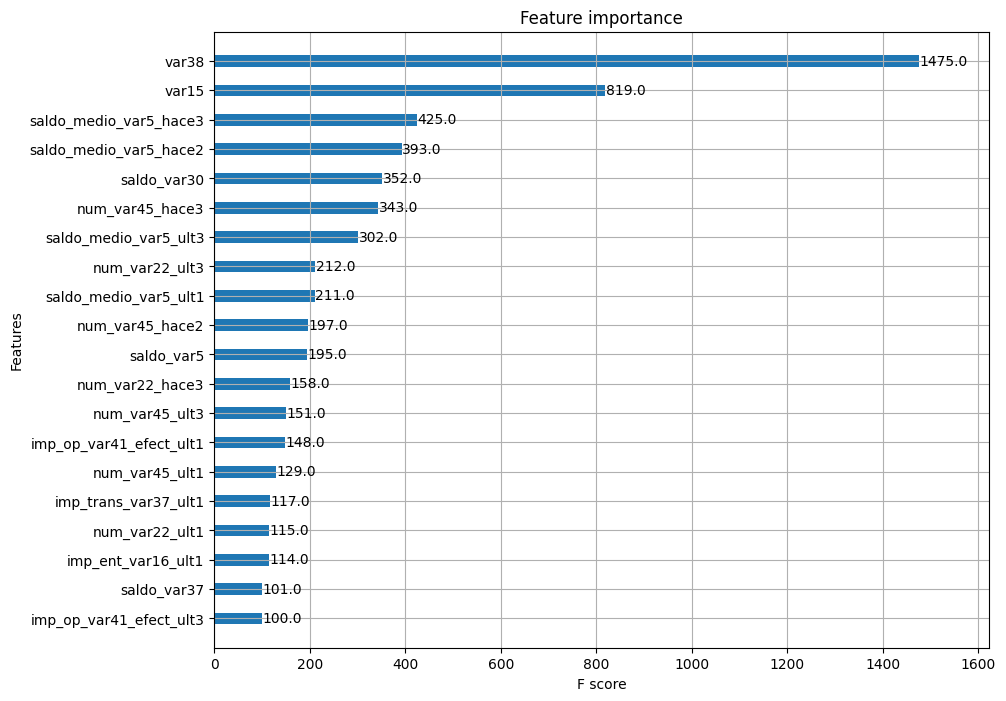

In [33]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize = (10, 8))
plot_importance(xgb_clf, ax = ax, max_num_features = 20, height = 0.4)